# How should neurons spend their spikes?

Spikes cost energy, and a brain has a limited number of neurons. If a sensory system could design
its own code, what would it choose? Barlow (1961) proposed an answer: represent the world with as
little redundancy as possible, so that each spike carries as much information as it can. That
principle, **efficient coding**, makes predictions about which stimuli we see or hear best.

**Part I · Foundations** builds the tools: entropy, mutual information, the optimal single neuron,
Fisher information for a population, and sparse codes.

**Part II · Case study** applies them to time. If neurons were allocated to durations according
to how often each duration occurs, what would discrimination look like?

| stage | question |
|---|---|
| 1. Cognitive phenomenon | What needs explaining? |
| 2. Behavioral experiment | How do we make it measurable? |
| 3. Empirical signature | What pattern in the data is the phenomenon? |
| 4. Computational model | What computation produces it, and can we identify it? |
| 5. Neural implementation | Could neurons carry it out? |
| 6. Prediction and failure | Which result would prove the model wrong? |

All data are simulated, so every analysis can be checked against the truth.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import norm

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
rng = np.random.default_rng(0)

# Part I · Foundations

## 1. Entropy: how surprising is the world?

Entropy measures the average surprise of a variable, in bits (Shannon, 1948):

$$H[s] = -\sum_s p(s)\log_2 p(s).$$

| symbol | meaning | array | shape |
|---|---|---|---|
| $s$ | a stimulus value, here a duration category | `s_cat` | (K,) |
| $p(s)$ | how often each value occurs | `p_s` | (K,) |
| $-\log_2 p(s)$ | surprise of one value: rare values surprise more | `-np.log2(p_s)` | (K,) |
| $H[s]$ | expected surprise | `-(p_s * np.log2(p_s)).sum()` | scalar |

A uniform distribution over $K$ values has the largest possible entropy, $\log_2 K$. Any
regularity lowers it.

In [2]:
def entropy(p):
    p = p[p > 0]
    return -(p * np.log2(p)).sum()


K = 8
p_uniform = np.full(K, 1 / K)                                     # (K,)
p_skewed = np.array([0.40, 0.25, 0.12, 0.08, 0.06, 0.04, 0.03, 0.02])   # (K,) short durations common
print(f"uniform: H = {entropy(p_uniform):.3f} bits  (log2 K = {np.log2(K):.3f})")
print(f"skewed:  H = {entropy(p_skewed):.3f} bits")

uniform: H = 3.000 bits  (log2 K = 3.000)
skewed:  H = 2.381 bits


## 2. Mutual information: how much does a response tell?

A neuron's response $x$ is useful to the extent that it reduces uncertainty about $s$. That
reduction is the **mutual information**:

$$I[s; x] = H[s] - H[s \mid x] = H[x] - H[x \mid s].$$

| term | meaning |
|---|---|
| $H[s \mid x]$ | uncertainty about the stimulus that remains after seeing the response |
| $H[x \mid s]$ | response variability for a fixed stimulus: the noise |
| $I[s;x]$ | what the response reveals about the stimulus |

A third way to write it says the same thing as a belief update. The KL divergence
$D[q \| p] = \sum q \log_2 (q/p)$ measures how far a belief moved. Mutual information is the average
distance from prior to posterior:

$$I[s;x] = \sum_x p(x)\, D\big[p(s\mid x)\,\|\,p(s)\big].$$

We compute all three for a noisy neuron and check that they agree.

In [3]:
# A noisy neuron with 6 response levels: response tends to grow with s
n_x = 6
lik = np.zeros((K, n_x))                                          # (K, X) p(x | s)
for k in range(K):
    center = k * (n_x - 1) / (K - 1)
    lik[k] = norm.pdf(np.arange(n_x), center, 0.9)
lik /= lik.sum(axis=1, keepdims=True)

p_s = p_skewed                                                    # (K,)
joint = p_s[:, None] * lik                                        # (K, X) p(s, x)
p_x = joint.sum(axis=0)                                           # (X,)
post = joint / p_x                                                # (K, X) p(s | x)

H_s_given_x = sum(p_x[j] * entropy(post[:, j]) for j in range(n_x))
H_x_given_s = sum(p_s[k] * entropy(lik[k]) for k in range(K))
kl = lambda q, p: (q[q > 0] * np.log2(q[q > 0] / p[q > 0])).sum()
I_kl = sum(p_x[j] * kl(post[:, j], p_s) for j in range(n_x))

print(f"H[s] - H[s|x] = {entropy(p_s) - H_s_given_x:.4f} bits")
print(f"H[x] - H[x|s] = {entropy(p_x) - H_x_given_s:.4f} bits")
print(f"mean KL(posterior || prior) = {I_kl:.4f} bits")

H[s] - H[s|x] = 0.6585 bits
H[x] - H[x|s] = 0.6585 bits
mean KL(posterior || prior) = 0.6585 bits


Three formulas, one number. Each view is useful: the first counts remaining uncertainty, the second
separates signal from noise, the third measures how much a response changes a belief.

## 3. The best single neuron equalizes its responses

Take a neuron with a limited number of distinguishable response levels and no noise. Which tuning
curve transmits the most information? A noise-free response carries $I[s;x] = H[x]$, and $H[x]$ is
largest when every response level is used equally often. The tuning curve that achieves that is the
**cumulative distribution** of the stimulus:

$$x(s) = L \cdot F(s), \qquad F(s) = P(S \le s).$$

Laughlin (1981) found that contrast responses of fly visual interneurons follow the cumulative
distribution of natural contrasts closely. This is called histogram equalization.

We test it on durations. Suppose durations in the world follow a skewed distribution, short ones
being common. Compare a linear tuning curve with the cumulative one, each quantized into 8 levels.

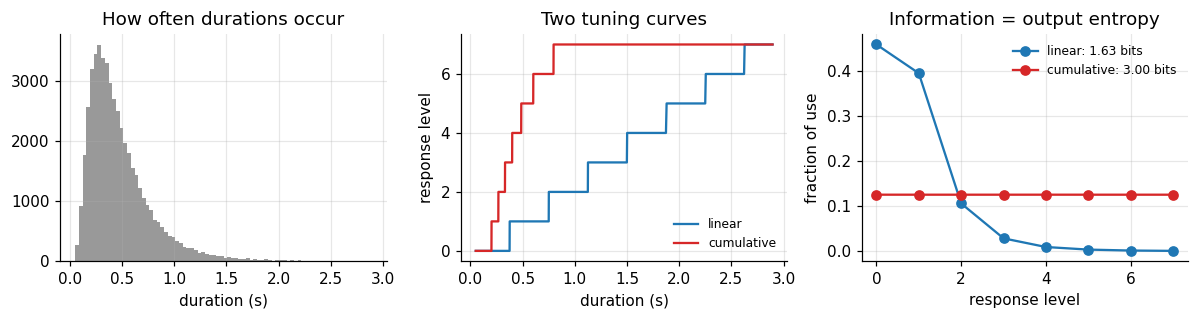

In [4]:
s_world = rng.lognormal(np.log(0.4), 0.6, 50_000)                 # (n,) durations in seconds
s_world = s_world[(s_world > 0.05) & (s_world < 3.0)]
L = 8

lin_resp = np.floor(s_world / 3.0 * L).clip(0, L - 1)             # (n,) linear tuning, 8 levels
ranks = np.argsort(np.argsort(s_world)) / s_world.size            # (n,) empirical F(s)
cdf_resp = np.floor(ranks * L).clip(0, L - 1)                     # (n,) cumulative tuning, 8 levels

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
axes[0].hist(s_world, bins=80, color="0.6")
axes[0].set(xlabel="duration (s)", title="How often durations occur")
order = np.argsort(s_world)
axes[1].plot(s_world[order], lin_resp[order], color="C0", label="linear")
axes[1].plot(s_world[order], cdf_resp[order], color="C3", label="cumulative")
axes[1].set(xlabel="duration (s)", ylabel="response level", title="Two tuning curves")
axes[1].legend(frameon=False, fontsize=8)
for resp, col, name in [(lin_resp, "C0", "linear"), (cdf_resp, "C3", "cumulative")]:
    use = np.bincount(resp.astype(int), minlength=L) / resp.size
    axes[2].plot(range(L), use, "o-", color=col, label=f"{name}: {entropy(use):.2f} bits")
axes[2].set(xlabel="response level", ylabel="fraction of use", title="Information = output entropy")
axes[2].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

The linear neuron wastes most of its levels on long durations that rarely occur. The cumulative
neuron uses all eight equally and reaches the maximum, $\log_2 8 = 3$ bits. With noise the optimum
changes: when responses are unreliable, the best code first averages away noise and then
equalizes (Atick & Redlich, 1992). The principle stays the same: spend resolution where the
stimuli are.

## 4. Fisher information for a population

For a population of Poisson neurons, the cleanest measure of local precision is the **Fisher
information**:

$$J(s) = T \sum_i \frac{f_i'(s)^2}{f_i(s)}.$$

| symbol | meaning | array | shape |
|---|---|---|---|
| $f_i(s)$ | tuning curve: expected rate of neuron $i$ for stimulus $s$ | `f` | (K, N) |
| $f_i'(s)$ | its slope: how much the rate changes when $s$ changes | `df` | (K, N) |
| $T$ | counting window | `T_win` | scalar |
| $J(s)$ | how sharply the population pins down $s$ near this value | `J` | (K,) |

A neuron contributes most where its tuning curve is steep, not where it fires most. The
Cramér-Rao bound turns $J$ into a limit on any unbiased decoder:
$\mathrm{SD}(\hat s) \ge 1/\sqrt{J(s)}$. We check the bound with a maximum likelihood decoder.

In [5]:
s_grid = np.linspace(0.05, 3.0, 1200)                             # (K,) fine grid of durations
N, r_max, base, T_win = 30, 40.0, 1.0, 0.5                        # neurons, peak Hz, baseline Hz, s


def population(centers_u, warp, width=0.05, rmax=r_max):
    # Gaussian tuning in a warped coordinate u = warp(s). Returns f and df on s_grid, both (K, N).
    u = warp(s_grid)
    du = np.gradient(u, s_grid)                                   # (K,) how fast u moves with s
    g = np.exp(-0.5 * ((u[:, None] - centers_u[None, :]) / width) ** 2)
    f = base + rmax * g
    df = rmax * g * (-(u[:, None] - centers_u[None, :]) / width ** 2) * du[:, None]
    return f, df


log_lo, log_hi = np.log(0.1), np.log(2.0)
log_warp = lambda s: (np.log(s) - log_lo) / (log_hi - log_lo)     # neurons evenly spaced in log time
centers = np.linspace(0, 1, N)
f_log, df_log = population(centers, log_warp)
J_log = T_win * (df_log ** 2 / f_log).sum(axis=1)                 # (K,)

# Check against a maximum likelihood decoder
test_s = np.array([0.2, 0.5, 1.0, 1.6])
sd_ml = []
for s0 in test_s:
    k0 = np.argmin(np.abs(s_grid - s0))
    counts = rng.poisson(f_log[k0] * T_win, size=(2000, N))       # (n, N)
    loglik = counts @ np.log(f_log.T * T_win) - (f_log * T_win).sum(axis=1)   # (n, K)
    sd_ml.append(s_grid[loglik.argmax(axis=1)].std())
for s0, sd in zip(test_s, sd_ml):
    print(f"s = {s0:.1f} s: ML decoder SD {sd * 1000:5.1f} ms, Cramér-Rao bound "
          f"{1000 / np.sqrt(np.interp(s0, s_grid, J_log)):5.1f} ms")

s = 0.2 s: ML decoder SD   3.8 ms, Cramér-Rao bound   3.8 ms
s = 0.5 s: ML decoder SD   9.5 ms, Cramér-Rao bound   9.5 ms
s = 1.0 s: ML decoder SD  19.1 ms, Cramér-Rao bound  19.0 ms
s = 1.6 s: ML decoder SD  33.5 ms, Cramér-Rao bound  32.6 ms


The decoder comes close to the bound. Both grow in proportion to $s$: a population spaced evenly in
log time is a Weber's law code. Keep that in mind for Part II.

## 5. Where to put the neurons

Section 3 said one neuron should equalize. For a population the same idea becomes a rule about
**density**: place tuning curves evenly in the cumulative coordinate $u = F(s)$. Then the density of
neurons follows $p(s)$, every neuron fires equally often on average, and the Fisher information
becomes

$$J(s) \propto p(s)^2, \qquad \text{discrimination threshold} \propto \frac{1}{\sqrt{J(s)}} \propto \frac{1}{p(s)}.$$

(Ganguli & Simoncelli, 2014.) Frequent stimuli get many narrow tuning curves, rare stimuli get
few broad ones. In code, the only change is the warp: `warp = F` instead of `log`.

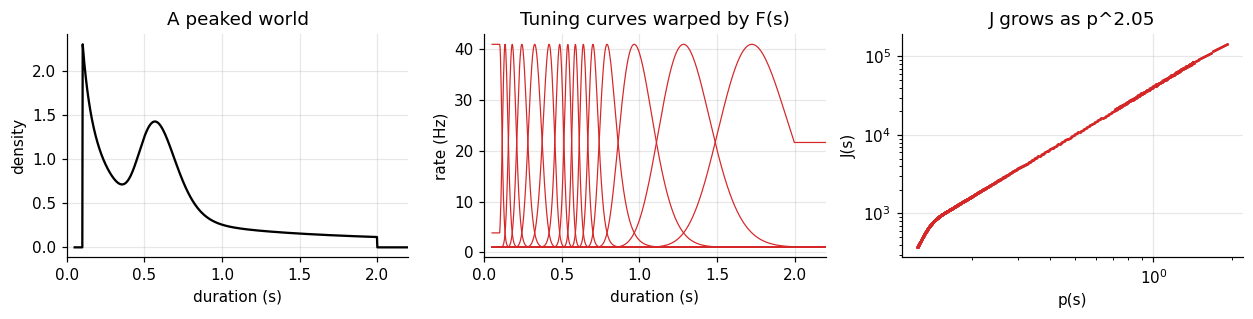

In [6]:
def make_prior(kind):
    # Duration distributions on s_grid, each normalized: (K,)
    if kind == "scale free":                                      # p(s) proportional to 1/s on 0.1 to 2 s
        p = np.where((s_grid >= 0.1) & (s_grid <= 2.0), 1 / s_grid, 0)
    else:                                                         # 70 percent scale free, 30 percent bump at 0.6 s
        p = 0.7 * make_prior("scale free") + 0.3 * norm.pdf(np.log(s_grid), np.log(0.6), 0.2) / s_grid
    return p / (p.sum() * (s_grid[1] - s_grid[0]))


def cdf_warp(p):
    F = np.cumsum(p) * (s_grid[1] - s_grid[0])
    return lambda s: np.interp(s, s_grid, F / F[-1])


p_peak = make_prior("peaked")
f_eff, df_eff = population(centers, cdf_warp(p_peak), width=0.03)
J_eff = T_win * (df_eff ** 2 / f_eff).sum(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3))
axes[0].plot(s_grid, p_peak, color="k")
axes[0].set(xlabel="duration (s)", ylabel="density", title="A peaked world", xlim=(0, 2.2))
axes[1].plot(s_grid, f_eff[:, ::2], color="C3", lw=0.8)
axes[1].set(xlabel="duration (s)", ylabel="rate (Hz)", title="Tuning curves warped by F(s)", xlim=(0, 2.2))
inside = (s_grid > 0.12) & (s_grid < 1.9)
axes[2].loglog(p_peak[inside], J_eff[inside], ".", color="C3", ms=2)
slope = np.polyfit(np.log(p_peak[inside]), np.log(J_eff[inside]), 1)[0]
axes[2].set(xlabel="p(s)", ylabel="J(s)", title=f"J grows as p^{slope:.2f}")
plt.tight_layout()
plt.show()

Tuning curves crowd around 0.6 s, and the Fisher information grows with the square of the
probability, as the formula says. Other objectives give other powers: minimizing squared error
instead of maximizing information changes the exponent, so the power itself is a testable property
of the code (Ganguli & Simoncelli, 2014).

## 6. Sparse codes

Efficient coding can also mean *few active neurons at a time*. A sparse code describes a signal
$\mathbf y$ as a combination of dictionary elements $\boldsymbol\phi_d$ with mostly zero weights
$v_d$:

$$\min_{\mathbf v}\; \lVert \mathbf y - \Phi \mathbf v \rVert^2 + \lambda \sum_d \lvert v_d\rvert.$$

The first term asks for an accurate description, the second for few active elements. Olshausen and
Field (1996) learned the dictionary from natural image patches and obtained receptive fields like
those of V1 simple cells. Here we keep the dictionary fixed and only look at the inference step,
solved by iterative shrinkage (ISTA): a gradient step, then shrink every weight toward zero.

least squares  active weights  75, fit error 0.317
sparse (ISTA)  active weights   8, fit error 0.453


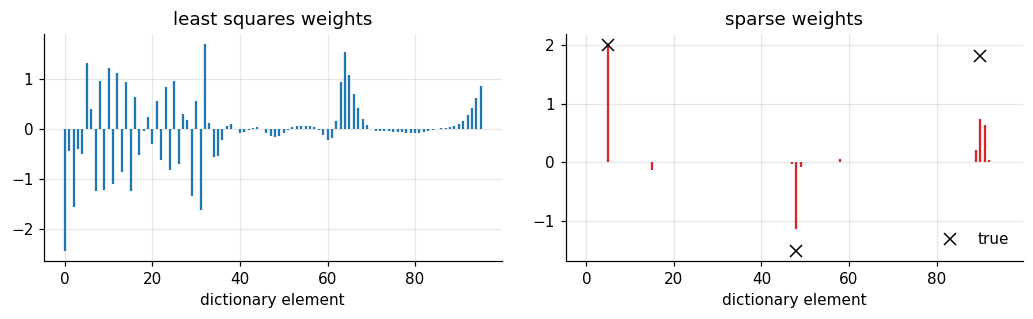

In [7]:
n_t, n_atoms = 64, 96                                          # 96 elements for 64 samples: overcomplete
tt = np.arange(n_t)
widths = np.repeat([2, 4, 8], n_atoms // 3)
centers_d = np.tile(np.linspace(0, n_t - 1, n_atoms // 3), 3)
Phi = np.exp(-0.5 * ((tt[:, None] - centers_d[None, :]) / widths[None, :]) ** 2)   # (n_t, D) bumps
Phi /= np.linalg.norm(Phi, axis=0)

active = [5, 48, 90]                                              # a narrow, a medium, and a wide bump
v_true = np.zeros(n_atoms); v_true[active] = [2.0, -1.5, 1.8]
y = Phi @ v_true + 0.05 * rng.normal(size=n_t)                   # (n_t,) observed signal

v_ls = np.linalg.pinv(Phi, rcond=1e-3) @ y                       # (D,) minimum norm least squares: dense

lam, step = 0.1, 1 / np.linalg.norm(Phi, 2) ** 2
v = np.zeros(n_atoms)
for _ in range(3000):                                             # ISTA
    v = v + step * Phi.T @ (y - Phi @ v)
    v = np.sign(v) * np.maximum(np.abs(v) - step * lam, 0)

for name, vv in [("least squares", v_ls), ("sparse (ISTA)", v)]:
    print(f"{name:14s} active weights {np.sum(np.abs(vv) > 0.05):3d}, "
          f"fit error {np.linalg.norm(y - Phi @ vv):.3f}")
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3))
axes[0].stem(v_ls, markerfmt=" ", basefmt=" ", linefmt="C0-")
axes[0].set(title="least squares weights", xlabel="dictionary element")
axes[1].stem(v, markerfmt=" ", basefmt=" ", linefmt="C3-")
axes[1].plot(active, v_true[active], "kx", ms=8, label="true")
axes[1].set(title="sparse weights", xlabel="dictionary element")
axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

Least squares fits the signal, noise included, by spreading weight over most elements. The sparse
solution uses a few, at and next to the three that made the signal, at the price of a slightly
larger fit error. Its weights are shrunk toward zero, the known cost of the $\lambda$ penalty. Fewer active
units means fewer spikes.

### What Part I gives us

- Entropy is average surprise; mutual information is the uncertainty a response removes.
- One neuron with few levels should follow the cumulative distribution of its stimulus.
- Fisher information $J(s) = T\sum_i f_i'^2/f_i$ bounds decoding precision at each stimulus value.
- Allocating tuning curves by $F(s)$ gives $J \propto p^2$: precision follows frequency.
- Sparse coding trades a little accuracy for far fewer active units.

# Part II · Case study: why are common durations discriminated best?

## Stage 1 · Cognitive phenomenon

Discrimination is not uniform across a stimulus dimension. For orientation, people discriminate
near horizontal and vertical better than oblique angles (the oblique effect; Appelle, 1972), and
cardinal orientations are also the most common in natural scenes. Efficient coding offers a single
explanation: more neurons where stimuli are frequent (Ganguli & Simoncelli, 2014; Wei & Stocker,
2015).

For time the best known pattern is Weber's law: discrimination thresholds grow in proportion to
the duration. Section 4 produced Weber's law from a log spaced population, and section 5 produces
precision proportional to probability. They meet in one observation: if durations in the world
are **scale free**, $p(s) \propto 1/s$, an efficient code has $J \propto 1/s^2$, which is Weber's
law. Weber's law could then be a consequence of the world's statistics rather than a fixed
property of the timing system.

The question: **is Weber's law for duration a fixed log code, or an efficient code adapted to the
durations one encounters?**

## Stage 2 · Behavioral experiment

Two groups do the same two-interval duration discrimination task: which of two intervals was
longer? Standards range from 0.15 to 1.4 s. Before testing, each group is exposed to many
durations from one environment:

- **scale free**: $p(s) \propto 1/s$ between 0.1 and 2 s;
- **peaked**: 70 percent from the same distribution, 30 percent from a bump around 0.6 s.

The simulated observers encode each interval with a Poisson population and decode by maximum
likelihood. An efficient observer allocates its 30 neurons by the cumulative distribution of its
environment.

In [8]:
standards = np.array([0.15, 0.25, 0.4, 0.6, 0.8, 1.1, 1.4])       # (S,) seconds
rel_steps = np.linspace(-0.3, 0.3, 13)                             # comparison = standard * (1 + step)
n_trials = 100
T_obs, rmax_obs = 0.25, 20.0                                       # a short window: precision near human levels


def observer(warp, width):
    f, _ = population(centers, warp, width, rmax=rmax_obs)
    return f * T_obs                                              # (K, N) expected counts


def decode(counts, F):
    loglik = counts @ np.log(F.T) - F.sum(axis=1)                 # (n, K)
    return s_grid[loglik.argmax(axis=1)]


def run_2ifc(F):
    # Returns P("comparison longer") with shape (S, C), and raw choices.
    P = np.zeros((standards.size, rel_steps.size))
    for a, s0 in enumerate(standards):
        k0 = np.argmin(np.abs(s_grid - s0))
        for b, st in enumerate(rel_steps):
            k1 = np.argmin(np.abs(s_grid - s0 * (1 + st)))
            e0 = decode(rng.poisson(F[k0], size=(n_trials, N)), F)
            e1 = decode(rng.poisson(F[k1], size=(n_trials, N)), F)
            P[a, b] = np.mean(e1 > e0) + 0.5 * np.mean(e1 == e0)
    return P


obs = {
    "efficient, scale free world": observer(cdf_warp(make_prior("scale free")), 0.15),
    "efficient, peaked world": observer(cdf_warp(make_prior("peaked")), 0.15),
    "fixed log code": observer(log_warp, 0.15),
}
P_choice = {name: run_2ifc(F) for name, F in obs.items()}
print({name: P.shape for name, P in P_choice.items()})

{'efficient, scale free world': (7, 13), 'efficient, peaked world': (7, 13), 'fixed log code': (7, 13)}


## Stage 3 · Empirical signature

For each standard we fit a cumulative Gaussian to the choice proportions (Foundations 4) and take
the threshold: the relative difference needed for 75 percent correct, the **Weber fraction** at
that standard.

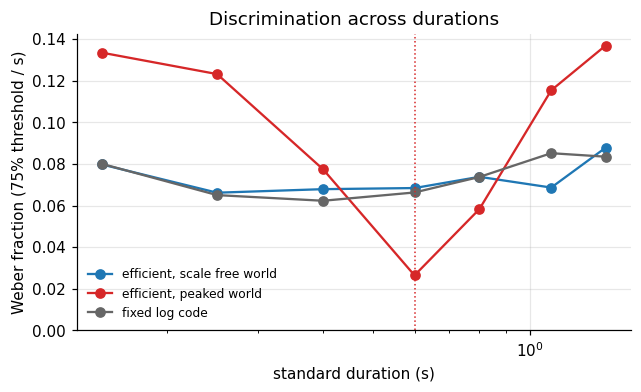

efficient, scale free world  [0.08  0.066 0.068 0.068 0.074 0.069 0.088]
efficient, peaked world      [0.134 0.123 0.077 0.026 0.058 0.115 0.137]
fixed log code               [0.08  0.065 0.062 0.066 0.074 0.085 0.084]


In [9]:
def weber_fraction(P_row):
    pf = lambda x, sig: norm.cdf(x / sig)
    sig, _ = curve_fit(pf, rel_steps, P_row, p0=[0.1], bounds=(1e-3, 2))
    return norm.ppf(0.75) * sig[0]                                # relative step for 75 percent


wf = {name: np.array([weber_fraction(P[a]) for a in range(standards.size)]) for name, P in P_choice.items()}
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for (name, w), col in zip(wf.items(), ["C0", "C3", "0.4"]):
    ax.plot(standards, w, "o-", color=col, label=name)
ax.axvline(0.6, color="C3", ls=":", lw=1)
ax.set(xlabel="standard duration (s)", ylabel="Weber fraction (75% threshold / s)", xscale="log",
       ylim=(0, None), title="Discrimination across durations")
ax.legend(frameon=False, fontsize=8)
plt.show()
for name, w in wf.items():
    print(f"{name:28s}", w.round(3))

Two patterns.

1. In the scale free world, the efficient observer's Weber fraction is roughly constant: Weber's
   law. The fixed log code shows the same flat line. **The two are indistinguishable here.**
2. In the peaked world, the Weber fraction dips near 0.6 s and rises elsewhere. The neurons moved
   to where durations are common.

## Stage 4 · Computational model

The model is section 5: neurons evenly spaced in $u = F(s)$, so $J(s) \propto p(s)^2$ and the
threshold is

$$\Delta(s) = c\, p(s)^{-\alpha/2}, \qquad \alpha = 2 \text{ for the information maximizing code}.$$

Here $c$ sets overall precision (number of neurons, window) and $\alpha$ says how strongly the code
follows the statistics. A fixed log code instead predicts $\Delta(s) = c\,s$ in every world.

**Identifiability.** Fit $\log \Delta = \log c - \tfrac{\alpha}{2}\log p(s)$ to each data set. In the
scale free world, $\log p(s) = -\log s + \text{const}$, so "follows the prior" and "follows log time"
are the same regressor. The exponent is recovered there, but it cannot tell the two models apart.
The peaked world separates them.

In [10]:
dens = {"scale free": make_prior("scale free"), "peaked": make_prior("peaked")}
for name, world in [("efficient, scale free world", "scale free"), ("efficient, peaked world", "peaked")]:
    thr = wf[name] * standards                                    # (S,) thresholds in seconds
    p_at = np.interp(standards, s_grid, dens[world])              # (S,) density at each standard
    slope, intercept = np.polyfit(np.log(p_at), np.log(thr), 1)
    print(f"{name:28s} judged against the {world:10s} density: alpha = {-2 * slope:.2f}")

# How well does each account predict the peaked world's thresholds? One free scale each.
thr_peak = wf["efficient, peaked world"] * standards
pred = {"efficient (p^-1)": 1 / np.interp(standards, s_grid, dens["peaked"]),
        "fixed log (s)": standards.copy()}
for name, shape in pred.items():
    c = np.exp(np.mean(np.log(thr_peak) - np.log(shape)))         # best scale on log axis
    rms = np.sqrt(np.mean((np.log(thr_peak) - np.log(c * shape)) ** 2))
    print(f"peaked data, {name:17s}: log RMS error {rms:.3f}")

efficient, scale free world  judged against the scale free density: alpha = 2.06
efficient, peaked world      judged against the peaked     density: alpha = 2.12
peaked data, efficient (p^-1) : log RMS error 0.126
peaked data, fixed log (s)    : log RMS error 0.557


In both worlds the fitted exponent comes out near 2. In the scale free world that number proves
little: the fixed log code, judged against the same density, would give it too, because the two
regressors are identical. In the peaked world the accounts come apart. With one free scale each,
the $1/p$ account predicts the thresholds with a log RMS error of about 0.13; the fixed log account,
which predicts a flat Weber fraction, misses by about 0.56.

The design lesson repeats from Foundations 10: a model can only be tested where its predictions
differ from its rivals'. A Weber's law experiment in a scale free world cannot test efficient
coding.

## Stage 5 · Neural implementation

An efficient code has to be learned, because the environment is not known in advance. Is there a
simple local rule that places neurons at the quantiles of the stimulus distribution?

One works with nothing but each neuron's own comparison. Neuron $i$ aims at quantile $q_i$. Each
time a stimulus arrives, the neuron moves its preferred duration $c_i$ (in log time) a little:

$$c_i \leftarrow c_i + \eta\,\big(q_i - \mathbb 1[s < c_i]\big).$$

If stimuli fall below $c_i$ more often than $q_i$, the neuron moves down; otherwise up. It settles
where exactly a fraction $q_i$ of stimuli fall below it, the $q_i$ quantile (Robbins & Monro, 1951).
No neuron needs to know the distribution.

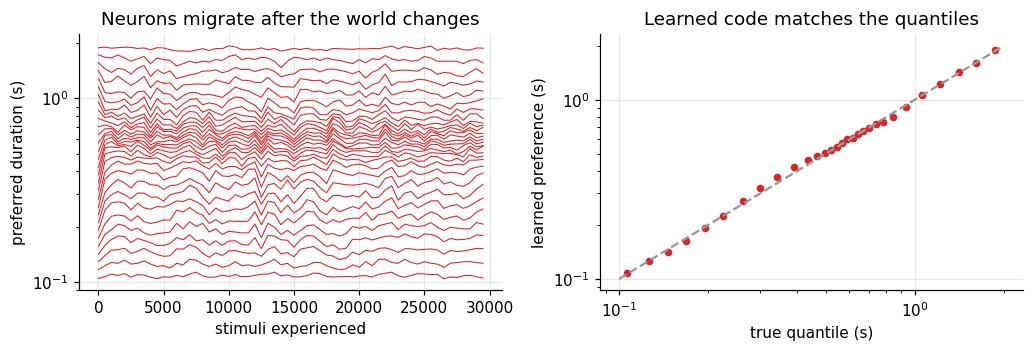

largest error after learning: 0.080 log units


In [11]:
q = (np.arange(N) + 0.5) / N                                      # (N,) target quantiles
c_log = np.quantile(np.log(rng.choice(s_grid, 20_000, p=dens["scale free"] / dens["scale free"].sum())), q)
eta, n_stream = 0.01, 30_000
stream = rng.choice(s_grid, n_stream, p=dens["peaked"] / dens["peaked"].sum())   # switch to the peaked world
history = np.empty((n_stream // 500, N))
for n_s, s_now in enumerate(stream):
    c_log += eta * (q - (np.log(s_now) < c_log))
    if n_s % 500 == 0:
        history[n_s // 500] = c_log

target = np.quantile(np.log(stream), q)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.3))
axes[0].plot(np.arange(history.shape[0]) * 500, np.exp(history), color="C3", lw=0.7)
axes[0].set(xlabel="stimuli experienced", ylabel="preferred duration (s)", yscale="log",
            title="Neurons migrate after the world changes")
axes[1].plot(np.exp(target), np.exp(c_log), "o", color="C3", ms=4)
axes[1].plot([0.1, 2], [0.1, 2], color="0.6", ls="--")
axes[1].set(xlabel="true quantile (s)", ylabel="learned preference (s)", xscale="log", yscale="log",
            title="Learned code matches the quantiles")
plt.tight_layout()
plt.show()
print(f"largest error after learning: {np.max(np.abs(c_log - target)):.3f} log units")

After the switch, neurons drift toward 0.6 s and stop at the quantiles of the new distribution. The
rule shows that an efficient code is **implementable** with local information. It does not show
that timing neurons use it. A causal test would track preferred durations in a timing circuit
before and after exposure, or block the plasticity and show that thresholds stop adapting.

## Stage 6 · Prediction and failure

| prediction | test | rejected if |
|---|---|---|
| Exposure to a peaked distribution lowers thresholds near the peak and raises them elsewhere. | thresholds before and after exposure | thresholds do not change, or change uniformly |
| The change follows $\Delta \propto p^{-1}$ (exponent near 2). | fit $\alpha$ across standards | a different exponent fits much better (another objective) |
| Adaptation takes time, set by the learning rate. | thresholds at several exposure lengths | the change is instantaneous (a decision strategy, not a code) |
| An efficient code decoded by a Bayesian observer biases estimates *away* from the peak (Wei & Stocker, 2015). | reproduction in the peaked world | estimates are pulled *toward* the peak only |

The last row is a real tension. Foundations 10 predicted attraction toward the prior. Efficient
encoding predicts that the same prior can produce repulsion. Which one wins depends on how strongly
the code is warped relative to how strongly the prior is used, and that is where the next tutorials
go.

One more failure is worth naming. The efficient observer here has perfect knowledge of the
environment after exposure. Real people may adapt only partly, and partial adaptation would show
up as an exponent between 0 and 2. That is not a rejection of efficient coding, but it is a
rejection of the version tested here.

## What to carry forward

- Information is reduction of uncertainty: $I[s;x] = H[s] - H[s\mid x]$.
- A single neuron with few levels transmits most by following the cumulative distribution.
- $J(s) = T\sum_i f_i'^2/f_i$; $1/\sqrt J$ bounds the decoder's precision.
- Allocate neurons by $F(s)$ and precision follows probability: $\Delta \propto 1/p(s)$.
- In a scale free world, that is Weber's law; only a non scale free world can tell an efficient code
  from a fixed log code.
- A local quantile rule can learn the code from experience.

## References

- Appelle, S. (1972). Perception and discrimination as a function of stimulus orientation: the
  "oblique effect" in man and animals. *Psychological Bulletin*, 78(4), 266 to 278.
- Atick, J. J., & Redlich, A. N. (1992). What does the retina know about natural scenes? *Neural
  Computation*, 4(2), 196 to 210.
- Barlow, H. B. (1961). Possible principles underlying the transformation of sensory messages. In
  W. A. Rosenblith (Ed.), *Sensory Communication* (pp. 217 to 234). MIT Press.
- Ganguli, D., & Simoncelli, E. P. (2014). Efficient sensory encoding and Bayesian inference with
  heterogeneous neural populations. *Neural Computation*, 26(10), 2103 to 2134.
- Laughlin, S. (1981). A simple coding procedure enhances a neuron's information capacity.
  *Zeitschrift für Naturforschung C*, 36(9 to 10), 910 to 912.
- Olshausen, B. A., & Field, D. J. (1996). Emergence of simple-cell receptive field properties by
  learning a sparse code for natural images. *Nature*, 381(6583), 607 to 609.
- Robbins, H., & Monro, S. (1951). A stochastic approximation method. *Annals of Mathematical
  Statistics*, 22(3), 400 to 407.
- Shannon, C. E. (1948). A mathematical theory of communication. *Bell System Technical Journal*,
  27(3), 379 to 423.
- Wei, X.-X., & Stocker, A. A. (2015). A Bayesian observer model constrained by efficient coding can
  explain "anti-Bayesian" percepts. *Nature Neuroscience*, 18(10), 1509 to 1517.